In [14]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/rays0n/items-human/items_human.parquet


In [15]:
from pathlib import Path

for p in Path("/kaggle/input").rglob("*.parquet"):
    print(p)

/kaggle/input/datasets/rays0n/items-human/items_human.parquet


In [16]:
items_paths = list(Path("/kaggle/input").rglob("items_human.parquet"))

ITEMS_PATH = items_paths[0]

In [17]:
items = pd.read_parquet(ITEMS_PATH)

display(items.head())

,id,name,attributes,category
0,197,victor reinz прокладка впускного коллектора ар...,"{""артикул"":""703315700"",""бренд"":""victor reinz"",...",Автотовары
1,415,"stellox диск тормозной, арт. 8500892sx","{""артикул"":""stellox_8500892sx"",""место установк...",Автотовары
2,427,комплект подшипника ступицы колеса lynxauto,"{""артикул производителя"":"""",""бренд"":""lynxauto""...",Автотовары
3,1027,"kraft подшипник ступицы, арт. kt204632, 1 шт.","{""артикул"":""112097-01"",""бренд"":""kraft"",""количе...",Автотовары
4,2639,фильтр салонный skoda fabia 00-,"{""альтернативные артикулы товара"":""8104400xkz9...",Автотовары


## Анализ длины текстовых полей: name, attributes (суммарно и по каждому ключу)

Цель — понять реальное распределение длин, чтобы обоснованно выбрать бюджеты обрезания (`MAX_NAME_CHARS`, `MAX_ATTR_CHARS`) и итоговый `MAX_SEQ_LENGTH` для токенизатора, без потери значимой информации на большей части товаров.

In [18]:
import json

def safe_json_loads(x):
    """Аккуратный парсинг JSON-строки attributes -> dict. Невалидные/пустые -> {}."""
    if not isinstance(x, str) or not x.strip():
        return {}
    try:
        obj = json.loads(x)
        return obj if isinstance(obj, dict) else {}
    except Exception:
        return {}

items['name'] = items['name'].fillna('').astype(str)
items['category'] = items['category'].fillna('').astype(str)
items['attributes'] = items['attributes'].fillna('').astype(str)

items['attrs_dict'] = items['attributes'].apply(safe_json_loads)

valid_json = items['attrs_dict'].apply(lambda d: len(d) > 0)
print(f"Валидных непустых attributes: {valid_json.mean():.2%} ({valid_json.sum():,} / {len(items):,})")

Валидных непустых attributes: 99.99% (711,232 / 711,304)


In [19]:
# Длина name: символы и слова
items['name_chars'] = items['name'].str.len()
items['name_words'] = items['name'].str.split().apply(len)

items[['name_chars', 'name_words']].describe(
    percentiles=[0.5, 0.75, 0.9, 0.95, 0.99, 0.999]
)

,name_chars,name_words
count,711304.000000,711304.00000
mean,57.675833,8.85901
std,30.357121,4.88677
min,1.000000,1.00000
50%,54.000000,8.00000
75%,71.000000,11.00000
90%,94.000000,15.00000
95%,113.000000,18.00000
99%,158.000000,24.00000
99.9%,234.000000,40.00000


In [20]:
# Собираем attributes в тот же текстовый формат "key: value key2: value2 ...",
# который реально используется в пайплайне (_create_product_text), чтобы статистика
# длины была релевантна фактическому инференсу, а не сырому JSON.
def attrs_to_text(attrs: dict) -> str:
    return " ".join(f"{k}: {v}" for k, v in attrs.items())

items['attrs_text'] = items['attrs_dict'].apply(attrs_to_text)
items['attrs_text_chars'] = items['attrs_text'].str.len()
items['attrs_raw_chars'] = items['attributes'].str.len()  # длина сырого JSON, для сравнения
items['n_attributes'] = items['attrs_dict'].apply(len)

items[['attrs_text_chars', 'attrs_raw_chars', 'n_attributes']].describe(
    percentiles=[0.5, 0.75, 0.9, 0.95, 0.99, 0.999]
)

,attrs_text_chars,attrs_raw_chars,n_attributes
count,711304.000000,711304.000000,711304.000000
mean,402.107314,442.298653,12.608200
std,593.750643,608.206723,8.228484
min,0.000000,2.000000,0.000000
50%,316.000000,353.000000,11.000000
75%,529.000000,584.000000,17.000000
90%,780.000000,852.000000,23.000000
95%,985.000000,1070.000000,27.000000
99%,1584.000000,1686.000000,39.000000
99.9%,3437.000000,3568.000000,55.000000


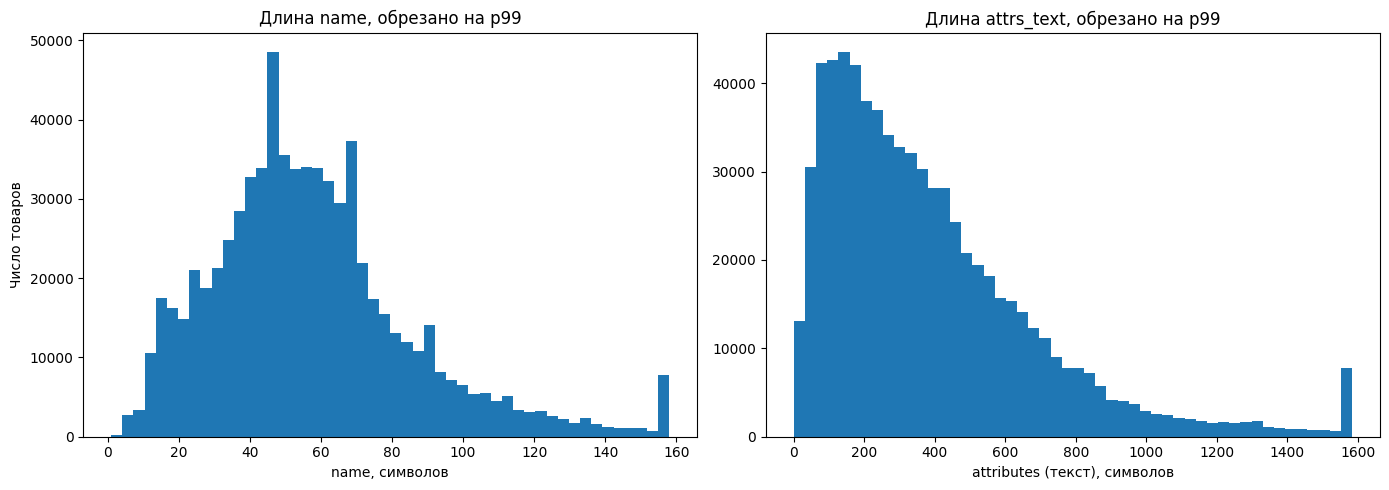

In [21]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

upper_name = items['name_chars'].quantile(0.99)
axes[0].hist(items['name_chars'].clip(upper=upper_name), bins=50)
axes[0].set_xlabel('name, символов')
axes[0].set_ylabel('Число товаров')
axes[0].set_title('Длина name, обрезано на p99')

upper_attrs = items['attrs_text_chars'].quantile(0.99)
axes[1].hist(items['attrs_text_chars'].clip(upper=upper_attrs), bins=50)
axes[1].set_xlabel('attributes (текст), символов')
axes[1].set_title('Длина attrs_text, обрезано на p99')

plt.tight_layout()
plt.show()

In [22]:
# Разворачиваем attributes в long-формат: (id, ключ, значение, длина значения),
# чтобы посчитать статистику длины КАЖДОГО атрибута по отдельности, а не суммарно.
# Внимание: на полном items.parquet (13М+ товаров) это может быть тяжело по памяти --
# для items_human (~711К) должно работать без проблем.
records = []
for item_id, attrs in zip(items['id'], items['attrs_dict']):
    for k, v in attrs.items():
        v_str = str(v)
        records.append((item_id, k, len(v_str)))

attrs_long = pd.DataFrame(records, columns=['id', 'attribute', 'value_chars'])
del records

print(f"Всего пар (item, attribute): {len(attrs_long):,}")
print(f"Уникальных ключей атрибутов: {attrs_long['attribute'].nunique():,}")

Всего пар (item, attribute): 8,968,263
Уникальных ключей атрибутов: 34,112


In [23]:
attr_key_stats = (
    attrs_long
    .groupby('attribute')['value_chars']
    .agg(
        count='count',
        mean='mean',
        median='median',
        p90=lambda x: x.quantile(0.90),
        p95=lambda x: x.quantile(0.95),
        p99=lambda x: x.quantile(0.99),
        max='max',
    )
    .sort_values('count', ascending=False)
)

# долю покрытия товаров данным ключом (частота встречаемости)
attr_key_stats['coverage'] = attr_key_stats['count'] / len(items)

print("Топ-30 атрибутов по частоте встречаемости:")
display(attr_key_stats.head(30))

print("\nТоп-20 атрибутов по СРЕДНЕЙ длине значения (кандидаты на отдельное урезание/исключение):")
display(
    attr_key_stats[attr_key_stats['count'] >= 100]  # отсекаем редкие ключи-шум
    .sort_values('mean', ascending=False)
    .head(20)
)

Топ-30 атрибутов по частоте встречаемости:


,count,mean,median,p90,p95,p99,max,coverage
attribute,,,,,,,,
тип,439850,14.131718,14.0,23.0,28.0,35.0,186,0.618371
бренд,369084,8.336856,8.0,12.0,15.0,21.0,825,0.518884
страна-изготовитель,284015,5.971998,6.0,7.0,8.0,14.0,24,0.399288
комплектация,265396,48.918330,30.0,97.0,126.0,287.0,55362,0.373112
цвет товара,257188,8.191494,7.0,12.0,14.0,22.0,134,0.361573
валюта,163743,3.000061,3.0,3.0,3.0,3.0,7,0.230201
страна производства,152058,6.095786,6.0,8.0,8.0,16.0,43,0.213774
пол,133153,7.634781,7.0,7.0,8.0,25.0,322,0.187196
материал,120393,10.018489,7.0,18.0,20.0,30.0,134,0.169257



Топ-20 атрибутов по СРЕДНЕЙ длине значения (кандидаты на отдельное урезание/исключение):


,count,mean,median,p90,p95,p99,max,coverage
attribute,,,,,,,,
список совместимых устройств,1707,2606.377270,67.0,6423.8,22764.30,32766.04,114511,0.002400
взаимодействие с другими препаратами,145,1955.717241,700.0,4859.2,7102.00,15523.64,19034,0.000204
особые указания,273,1647.124542,573.0,4037.0,7619.80,16574.92,25475,0.000384
побочное действие,130,1640.076923,1054.0,3953.7,5006.20,7075.81,8790,0.000183
фармакологическое действие,198,1311.353535,757.0,2822.9,4157.70,8743.72,12350,0.000278
о главном камне украшения,5360,523.856716,545.0,628.0,628.00,628.00,662,0.007535
передозировка,155,504.354839,320.0,1324.0,1487.30,2636.42,4895,0.000218
как читать характеристику бриллианта,2223,479.000000,479.0,479.0,479.00,479.00,479,0.003125
совместимые модели телевизоров,202,414.430693,43.5,1293.7,1955.55,4064.37,5088,0.000284


In [24]:
# Полный текст товара в формате пайплайна: "Name: ... Category: ... Attributes: ..."
items['full_text'] = (
    'Name: ' + items['name']
    + ' Category: ' + items['category']
    + ' Attributes: ' + items['attrs_text']
)
items['full_text_chars'] = items['full_text'].str.len()

items['full_text_chars'].describe(
    percentiles=[0.5, 0.75, 0.9, 0.95, 0.99, 0.999]
)

count    711304.000000
mean        503.701451
std         596.871762
min          49.000000
50%         414.000000
75%         629.000000
90%         886.000000
95%        1103.000000
99%        1716.000000
99.9%      3599.000000
max      114867.000000
Name: full_text_chars, dtype: float64

In [25]:
# Разбивка по категориям -- структура attributes сильно отличается между категориями
# (например, автозапчасти vs. одежда), это может обосновать разные бюджеты обрезания
# по категориям вместо единого MAX_ATTR_CHARS на всё.
category_len_stats = (
    items
    .groupby('category')
    .agg(
        items=('id', 'count'),
        name_chars_median=('name_chars', 'median'),
        name_chars_p95=('name_chars', lambda x: x.quantile(0.95)),
        attrs_chars_median=('attrs_text_chars', 'median'),
        attrs_chars_p95=('attrs_text_chars', lambda x: x.quantile(0.95)),
        n_attrs_median=('n_attributes', 'median'),
    )
    .sort_values('attrs_chars_p95', ascending=False)
)

display(category_len_stats)

,items,name_chars_median,name_chars_p95,attrs_chars_median,attrs_chars_p95,n_attrs_median
category,,,,,,
Электроника,34455,60.0,176.0,407.0,1474.00,14.0
Ювелирные изделия,34759,57.0,109.0,458.0,1465.00,16.0
Товары для животных,35663,66.0,118.0,366.0,1455.00,12.0
Бытовая техника,34887,48.0,90.0,509.0,1294.00,17.0
Красота и гигиена,34299,57.0,99.0,256.0,1136.00,8.0
Мебель,35505,61.0,141.0,591.0,1094.00,21.0
Продукты питания,35564,54.0,100.0,510.0,958.00,14.0
Аптека,35620,81.0,130.0,452.0,861.00,15.0
Спорт и отдых,35084,54.0,97.0,196.0,848.00,8.0


In [26]:
# Ключевой момент: обрезание в пайплайне происходит НА УРОВНЕ ТОКЕНОВ (max_length у tokenizer),
# а не символов. Чтобы перевести перцентили символов в реальный token-бюджет,
# токенизируем выборку тем же токенизатором, что и в проде.
try:
    from transformers import AutoTokenizer

    tokenizer = AutoTokenizer.from_pretrained('cross-encoder/ms-marco-MiniLM-L-12-v2')

    sample = items.sample(min(5000, len(items)), random_state=42)

    def n_tokens(text):
        return len(tokenizer.encode(text, add_special_tokens=False))

    sample_token_len = sample['full_text'].apply(n_tokens)
    sample_char_len = sample['full_text_chars']

    chars_per_token = (sample_char_len / sample_token_len.replace(0, np.nan)).median()

    print(f"Медианное отношение символов/токен: {chars_per_token:.2f}")
    print()
    print("Распределение числа токенов на full_text (без спецтокенов):")
    display(
        sample_token_len.describe(percentiles=[0.5, 0.75, 0.9, 0.95, 0.99, 0.999])
    )
except Exception as e:
    print(f"Токенизатор недоступен в этом окружении ({e}). "
          "Символьную статистику выше можно грубо делить на ~2-3 (эмпирическое "
          "отношение символ/токен для смешанного RU/EN текста), но точный расчёт "
          "нужен именно через реальный tokenizer перед финальным выбором MAX_SEQ_LENGTH.")

'[Errno -3] Temporary failure in name resolution' thrown while requesting HEAD https://huggingface.co/cross-encoder/ms-marco-MiniLM-L-12-v2/resolve/main/config.json
Retrying in 1s [Retry 1/5].
'[Errno -3] Temporary failure in name resolution' thrown while requesting HEAD https://huggingface.co/cross-encoder/ms-marco-MiniLM-L-12-v2/resolve/main/config.json
Retrying in 1s [Retry 1/5].


Токенизатор недоступен в этом окружении (Can't load the configuration of 'cross-encoder/ms-marco-MiniLM-L-12-v2'. If you were trying to load it from 'https://huggingface.co/models', make sure you don't have a local directory with the same name. Otherwise, make sure 'cross-encoder/ms-marco-MiniLM-L-12-v2' is the correct path to a directory containing a config.json file). Символьную статистику выше можно грубо делить на ~2-3 (эмпирическое отношение символ/токен для смешанного RU/EN текста), но точный расчёт нужен именно через реальный tokenizer перед финальным выбором MAX_SEQ_LENGTH.


In [27]:
# Сводная таблица перцентилей по всем ключевым полям в одном месте
def pct_row(series, label):
    qs = [0.5, 0.75, 0.9, 0.95, 0.99, 0.999]
    row = {f'p{q*100:g}': series.quantile(q) for q in qs}
    row['mean'] = series.mean()
    row['max'] = series.max()
    return pd.Series(row, name=label)

summary = pd.concat(
    [
        pct_row(items['name_chars'], 'name_chars'),
        pct_row(items['attrs_text_chars'], 'attrs_text_chars'),
        pct_row(items['n_attributes'], 'n_attributes'),
        pct_row(items['full_text_chars'], 'full_text_chars'),
    ],
    axis=1,
).T

display(summary)

,p50,p75,p90,p95,p99,p99.9,mean,max
name_chars,54.0,71.0,94.0,113.0,158.0,234.0,57.675833,4126.0
attrs_text_chars,316.0,529.0,780.0,985.0,1584.0,3437.0,402.107314,114775.0
n_attributes,11.0,17.0,23.0,27.0,39.0,55.0,12.608200,113.0
full_text_chars,414.0,629.0,886.0,1103.0,1716.0,3599.0,503.701451,114867.0


## Как читать результат и на что опираться при выборе бюджетов обрезания

После запуска ячеек выше подставьте фактические числа из вашей сводной таблицы (`summary`) и таблицы `attr_key_stats` в рассуждение ниже -- цифры зависят от реального датасета (`items_human.parquet` содержит только товары с ручной разметкой, полный `items.parquet` может иметь другое распределение).

**Общий принцип выбора бюджета**: не пытайтесь покрыть 100% товаров без обрезания (p99.9/max) -- длинный хвост из редких выбросов задаёт неоправданно большой `MAX_LENGTH`, что замедляет инференс для всех товаров ради единиц процентов. Стандартная практика -- ориентироваться на **p90-p95**: осознанно жертвовать частью информации у 5-10% самых длинных товаров, но не раздувать бюджет токенов.

**Порядок действий:**
1. Возьмите `p95` (или `p90`, если критична скорость) для `name_chars` -> это кандидат на `MAX_NAME_CHARS`.
2. Возьмите `p95` для `attrs_text_chars` -> кандидат на `MAX_ATTR_CHARS`. Если `attr_key_stats`    показывает, что 1-2 ключа (например, длинное текстовое описание) дают основной вклад в длину    и при этом слабо информативны для матчинга -- рассмотрите их точечное исключение или отдельный,    более жёсткий лимит именно для этих ключей, вместо урезания всех атрибутов одинаково.
3. **Переведите итоговый символьный бюджет в токены** через отношение `chars_per_token`, посчитанное    реальным токенизатором (ячейка выше) -- это единственный надёжный способ узнать, сколько токенов    займёт текст на практике для смешанного RU/EN контента с артикулами и брендами.
4. Помните, что для cross-encoder'а `MAX_SEQ_LENGTH` -- это бюджет **на пару** (id1 + id2 вместе).    Если модель поддерживает 512 токенов (см. `config.json`), грубый ориентир -- **(512 - 3) / 2 ≈ 254    токена на один товар**, а не 512 на каждый. Если распределение длины между id1/id2 в паре    асимметрично, стоит закладывать не строго поровну, а с запасом под более длинный из двух.
5. Если разбивка по категориям (`category_len_stats`) показывает сильный разброс -- у автозапчастей    атрибутов обычно значительно больше, чем в одежде/обуви -- рассмотрите **адаптивный бюджет    по категории** вместо единого `MAX_ATTR_CHARS` на весь датасет: так вы не будете ни излишне    обрезать «богатые на атрибуты» категории, ни тратить токены впустую на категории с короткими    атрибутами.